# Do low-impedance bonds come in discrete impedance categories, or is it a measurement artifact?

Note in `active_bonding_notes.md`: *"this quantization I often see as if there are categories of bonds? or measurement artifacts?"*

**How the impedance is computed** (`record_imp.process_impedance_recording`):
`Z = amplitude_uV / (DAC_amplitude * LSB_nA / 1000)`, i.e. measured voltage amplitude on the electrode
divided by the *nominal* injected current. The injected current depends on the per-stim-unit LSB calibration;
the voltage is a sine fit over 400 cycles. Candidate explanations for clusters in Z:

| # | hypothesis | prediction |
|---|---|---|
| H1 | ADC / amplitude quantization | Z levels equally spaced in *linear* Z; amplitude sits on a raw-LSB grid |
| H2 | DAC amplitude steps | would need DAC amplitude to vary between electrodes (it is fixed here) |
| H3 | per-stim-unit current (LSB) error | clusters align with stim unit; within a unit Z is tight |
| H4 | routing / position on the chip (switch matrix, line length) | Z depends on x / y of the MEA1K electrode |
| H5 | real bond classes (e.g. metal-1 vs metal-2 contact, pillar contact vs. not) | clusters persist for the same electrode across repeated runs, are not explained by stim unit |

Key test: **repeatability**. A measurement artifact reshuffles between runs, a physical class does not.

In [1]:
import os, sys
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.mixture import GaussianMixture

sys.path.append(os.path.join('..',)); sys.path.append(os.path.join('..','..'))
from baseVR.base_functionality import device_paths
from mea1k_utils import load_impedance_data

nas_dir = device_paths()[0]
plt.rcParams.update({'figure.dpi':100,'axes.grid':True,'grid.alpha':.3})

# (headstage, rec_dir, label) -- imp recordings referenced at the end of bonds3_MEA27_elevGold.py
RUNS = [
 ('MEA1K27','2026-11-10_15.26_test16_100k_36umP_PT3_Imp','MEA27 D0'),
 ('MEA1K27','2026-11-13_14.48_test16_100k_36umP_PT3_Imp','MEA27 D3'),
 ('MEA1K24','2026-11-11_15.10_test17_100_36umP_PT5_Imp','MEA24 D0'),
 ('MEA1K24','2026-11-17_10.12_test17_100_36umP_PT5_Imp','MEA24 D6'),
 ('MEA1K24','2026-11-18_16.22_test17_100_36umP_PT5_Imp','MEA24 D7'),
 ('MEA1K23','2026-11-10_17.12_test14_100k_36umP_PT3_Imp','MEA23 D0'),
 ('MEA1K23','2026-11-11_16.28_test14_100k_36umP_PT3_Imp','MEA23 D2'),
 ('MEA1K23','2026-11-12_15.00_test14_100k_36umP_PT3_Imp','MEA23 D3'),
 ('MEA1K23','2026-11-17_11.31_test14_100k_36umP_PT3_Imp','MEA23 D7'),
]
D = {}
for hs, rd, lab in RUNS:
    df,_,_ = load_impedance_data(rd, nas_dir, f'devices/headstage_devices/{hs}/recordings')
    df['x'] = (df.electrode % 220)*17.5; df['y'] = (df.electrode // 220)*17.5
    df['Z'] = df.impedance_Ohm; df['logZ'] = np.log10(df.Z); df['run']=lab
    D[lab] = df
for k,v in D.items():
    print(f'{k:10s} n={len(v):5d}  DAC amp={sorted(v.stim_sequence_DAC_amplitude.unique())}  '
          f'modes={v.stim_mode.unique()}  f={v.stim_sequence_frequency_Hz.unique()}Hz  '
          f'n(Z<20k)={int((v.Z<20e3).sum())}')

Implant mapping file not found: /mnt/SpatialSequenceLearning/devices/implant_devices/bonding/bonding_mapping_.csv
Implant mapping file not found: /mnt/SpatialSequenceLearning/devices/implant_devices/bonding/bonding_mapping_.csv
Implant mapping file not found: /mnt/SpatialSequenceLearning/devices/implant_devices/bonding/bonding_mapping_.csv
Implant mapping file not found: /mnt/SpatialSequenceLearning/devices/implant_devices/bonding/bonding_mapping_.csv
Implant mapping file not found: /mnt/SpatialSequenceLearning/devices/implant_devices/bonding/bonding_mapping_.csv
Implant mapping file not found: /mnt/SpatialSequenceLearning/devices/implant_devices/bonding/bonding_mapping_.csv
Implant mapping file not found: /mnt/SpatialSequenceLearning/devices/implant_devices/bonding/bonding_mapping_.csv
Implant mapping file not found: /mnt/SpatialSequenceLearning/devices/implant_devices/bonding/bonding_mapping_.csv
Implant mapping file not found: /mnt/SpatialSequenceLearning/devices/implant_devices/bon

MEA27 D0   n= 2828  DAC amp=[30]  modes=['large_current']  f=[1000]Hz  n(Z<20k)=2764
MEA27 D3   n= 2892  DAC amp=[30]  modes=['large_current']  f=[1000]Hz  n(Z<20k)=2793
MEA24 D0   n= 1838  DAC amp=[30]  modes=['large_current']  f=[1000]Hz  n(Z<20k)=1590
MEA24 D6   n= 1742  DAC amp=[30]  modes=['large_current']  f=[1000]Hz  n(Z<20k)=1535
MEA24 D7   n= 1742  DAC amp=[30]  modes=['large_current']  f=[1000]Hz  n(Z<20k)=1537
MEA23 D0   n= 3215  DAC amp=[30]  modes=['large_current']  f=[1000]Hz  n(Z<20k)=3122
MEA23 D2   n= 3367  DAC amp=[30]  modes=['large_current']  f=[1000]Hz  n(Z<20k)=3113
MEA23 D3   n= 3375  DAC amp=[30]  modes=['large_current']  f=[1000]Hz  n(Z<20k)=3102
MEA23 D7   n= 3279  DAC amp=[30]  modes=['large_current']  f=[1000]Hz  n(Z<20k)=3119


## 1. The distribution: histograms of the low-Z population
Z < 20 kΩ is the well-bonded population (the few points at 50–200 kΩ are unbonded/other). Linear and log axes, two bin widths, so a structure that only appears at one binning is visible as such.

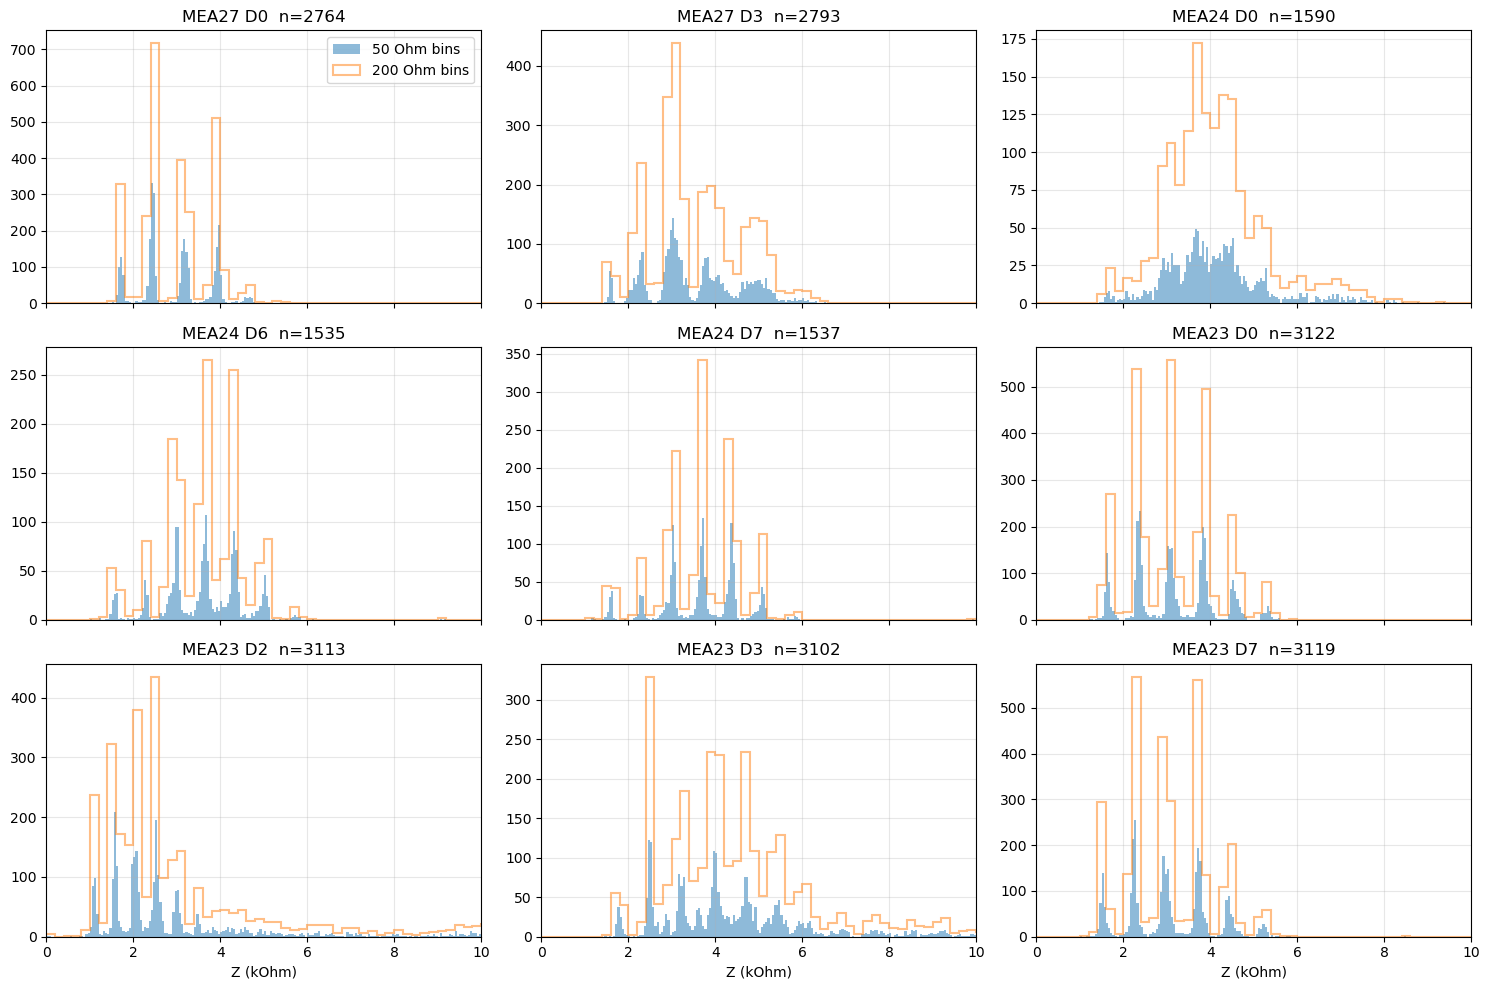

In [2]:
LOW = 20e3
fig, axs = plt.subplots(3, 3, figsize=(15, 10), sharex=True)
for ax,(k,v) in zip(axs.flat, D.items()):
    z = v.Z[v.Z<LOW]/1e3
    ax.hist(z, bins=np.arange(0,LOW/1e3,.05), color='C0', alpha=.5, label='50 Ohm bins')
    ax.hist(z, bins=np.arange(0,LOW/1e3,.2), color='C1', alpha=.5, histtype='step', lw=1.5, label='200 Ohm bins')
    ax.set_title(f'{k}  n={len(z)}'); ax.set_xlim(0,10)
    if ax in axs[-1]: ax.set_xlabel('Z (kOhm)')
axs[0,0].legend()
plt.tight_layout(); plt.show()

## 2. Is it multimodal at all? Silverman test + GMM BIC
Count the modes of a Gaussian KDE of log Z. Silverman's critical-bandwidth bootstrap gives a p-value for "more modes than *k*". The GMM BIC is shown too, but note BIC happily splits skewed unimodal distributions into several components, so the Silverman test is the stricter one.

In [3]:
def n_modes(x, h, grid):
    d = stats.gaussian_kde(x, bw_method=h/x.std(ddof=1))(grid)
    return int(((d[1:-1]>d[:-2])&(d[1:-1]>d[2:])).sum())

def silverman_p(x, k=1, nboot=300, seed=0):
    rng = np.random.default_rng(seed)
    grid = np.linspace(x.min()-3*x.std(), x.max()+3*x.std(), 600)
    lo, hi = 1e-4, x.std()*2
    for _ in range(30):                      # smallest h with <=k modes
        mid=(lo+hi)/2
        if n_modes(x, mid, grid)<=k: hi=mid
        else: lo=mid
    hk = hi; cnt = 0
    for _ in range(nboot):
        xs = rng.choice(x, len(x)); xs = xs.mean() + (xs-xs.mean()+hk*rng.standard_normal(len(x)))/np.sqrt(1+hk**2/x.var())
        cnt += n_modes(xs, hk, grid) > k
    return hk, cnt/nboot

rows=[]
for k,v in D.items():
    x = v.logZ[v.Z<LOW].values
    hk,p1 = silverman_p(x,1)
    bic = {n: GaussianMixture(n, random_state=0, n_init=3).fit(x[:,None]).bic(x[:,None]) for n in range(1,7)}
    rows.append(dict(run=k, n=len(x), modes_at_h_small=n_modes(x, .02, np.linspace(x.min(),x.max(),600)),
                     silverman_p_unimodal=p1, bestBIC_k=min(bic,key=bic.get)))
pd.DataFrame(rows).round(3)

,run,n,modes_at_h_small,silverman_p_unimodal,bestBIC_k
0,MEA27 D0,2764,4,0.000,6
1,MEA27 D3,2793,6,0.017,6
2,MEA24 D0,1590,9,0.007,5
3,MEA24 D6,1535,8,0.177,6
4,MEA24 D7,1537,8,0.120,6
5,MEA23 D0,3122,8,0.053,6
6,MEA23 D2,3113,16,0.000,6
7,MEA23 D3,3102,10,0.000,6
8,MEA23 D7,3119,7,0.003,6


## 3. Repeatability: do the same electrodes land in the same category on the next run?
If clusters were a per-measurement artifact (noise, timing, fit), an electrode's position would change from run to run. We compare consecutive runs of the same chip: scatter of log Z (run A vs run B), correlation, and the **repeat noise** (std of Δlog Z) versus the **spread of the population**.

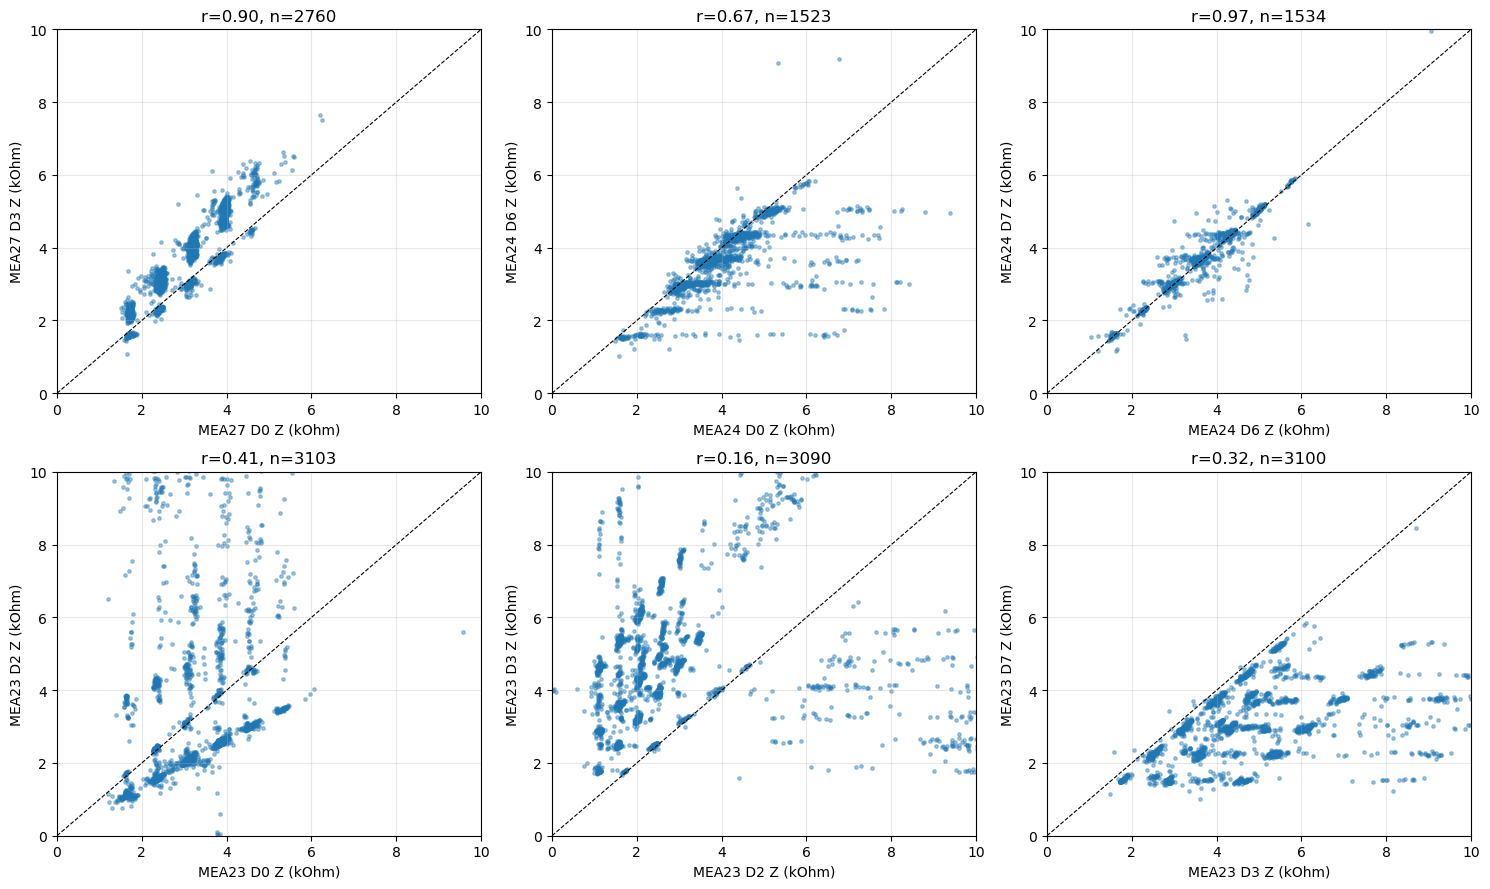

,A,B,n,r_logZ,pop_std_logZ,repeat_std_logZ,drift_median
0,MEA27 D0,MEA27 D3,2760,0.903,0.123,0.058,0.089
1,MEA24 D0,MEA24 D6,1523,0.674,0.127,0.103,-0.023
2,MEA24 D6,MEA24 D7,1534,0.967,0.128,0.033,0.005
3,MEA23 D0,MEA23 D2,3103,0.415,0.143,0.264,-0.171
4,MEA23 D2,MEA23 D3,3090,0.164,0.289,0.341,0.242
5,MEA23 D3,MEA23 D7,3100,0.319,0.234,0.233,-0.121


In [4]:
pairs = [('MEA27 D0','MEA27 D3'),('MEA24 D0','MEA24 D6'),('MEA24 D6','MEA24 D7'),
         ('MEA23 D0','MEA23 D2'),('MEA23 D2','MEA23 D3'),('MEA23 D3','MEA23 D7')]
fig, axs = plt.subplots(2, 3, figsize=(15, 9))
summ=[]
for ax,(a,b) in zip(axs.flat, pairs):
    m = D[a].merge(D[b], on='electrode', suffixes=('_a','_b'))
    m = m[(m.Z_a<LOW)&(m.Z_b<LOW)]
    r = np.corrcoef(m.logZ_a,m.logZ_b)[0,1]; d = m.logZ_b-m.logZ_a
    ax.scatter(m.Z_a/1e3, m.Z_b/1e3, s=6, alpha=.4); ax.plot([0,10],[0,10],'k--',lw=.8)
    ax.set_xlim(0,10); ax.set_ylim(0,10); ax.set_xlabel(f'{a} Z (kOhm)'); ax.set_ylabel(f'{b} Z (kOhm)')
    ax.set_title(f'r={r:.2f}, n={len(m)}')
    summ.append(dict(A=a,B=b,n=len(m),r_logZ=r, pop_std_logZ=m.logZ_a.std(), repeat_std_logZ=d.std(), drift_median=d.median()))
plt.tight_layout(); plt.show()
pd.DataFrame(summ).round(3)

## 4. Within-run replicate-free noise floor: what does one *measurement* of Z cost?
Is there a measurement-resolution reason for a grid? Z = V/(n·LSB_nA): the voltage amplitude is a fit over 400 cycles of a sine, so it is continuous unless it is limited by raw ADC bits. Look at the amplitude actually measured and at the (assumed) ADC step.

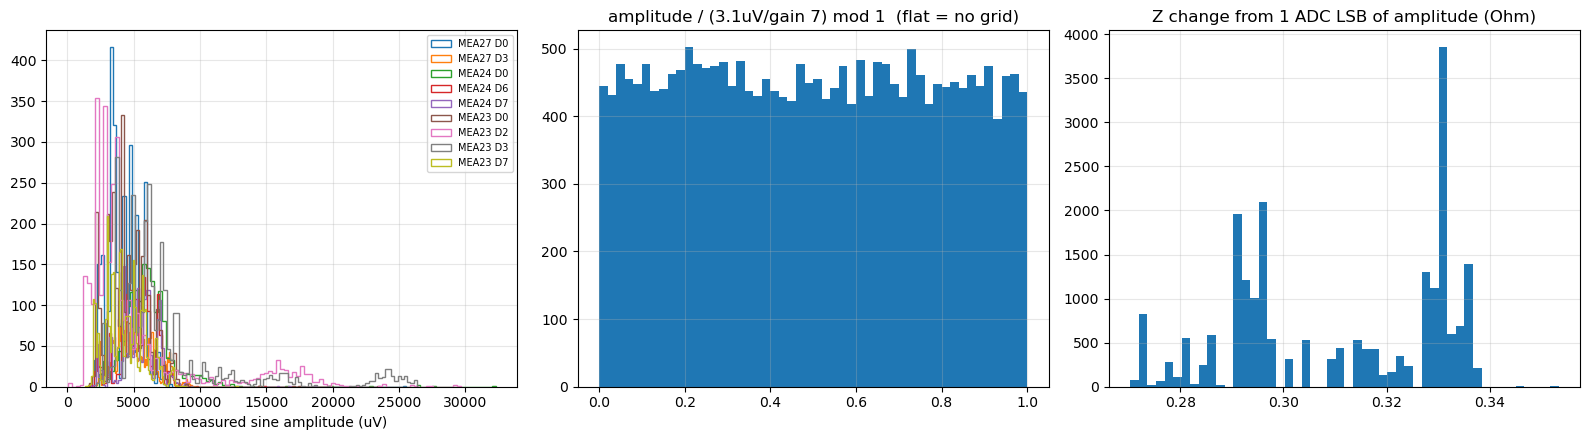

median amplitude 4789 uV = 10814 ADC LSB(input-referred);  1 LSB -> dZ=0.3 Ohm


In [5]:
ADC_LSB_uV = 3.1   # ASSUMPTION: MaxWell MEA1K ADC step at the amplifier output ~3.1 uV (referred to input: /gain). check!
fig, axs = plt.subplots(1, 3, figsize=(16, 4.5))
for k,v in D.items():
    s = v[v.Z<LOW]
    axs[0].hist(s.amplitude_uV, bins=100, histtype='step', label=k)
axs[0].set_xlabel('measured sine amplitude (uV)'); axs[0].legend(fontsize=7)
v = pd.concat([D[k][D[k].Z<LOW] for k in D])
g = v.gain.iloc[0]; lsb_in = ADC_LSB_uV/g
axs[1].hist(((v.amplitude_uV/lsb_in)%1), bins=50); axs[1].set_title(f'amplitude / ({ADC_LSB_uV}uV/gain {g}) mod 1  (flat = no grid)')
step = lsb_in/(v.stim_sequence_DAC_amplitude*v.LSB_nA/1000)  # Z step (Ohm) caused by one raw ADC LSB of amplitude
axs[2].hist(step, bins=50); axs[2].set_title('Z change from 1 ADC LSB of amplitude (Ohm)')
plt.tight_layout(); plt.show()
print(f'median amplitude {v.amplitude_uV.median():.0f} uV = {v.amplitude_uV.median()/lsb_in:.0f} ADC LSB(input-referred);  1 LSB -> dZ={step.median():.1f} Ohm')

## 5. Stim unit (H3): does the injected-current calibration make the clusters?
Each stim unit has its own LSB (nA/step). If the LSB is wrong by a few % for a unit, *all* its electrodes shift together. Show Z per stim unit and the fraction of log-Z variance explained by stim unit identity.

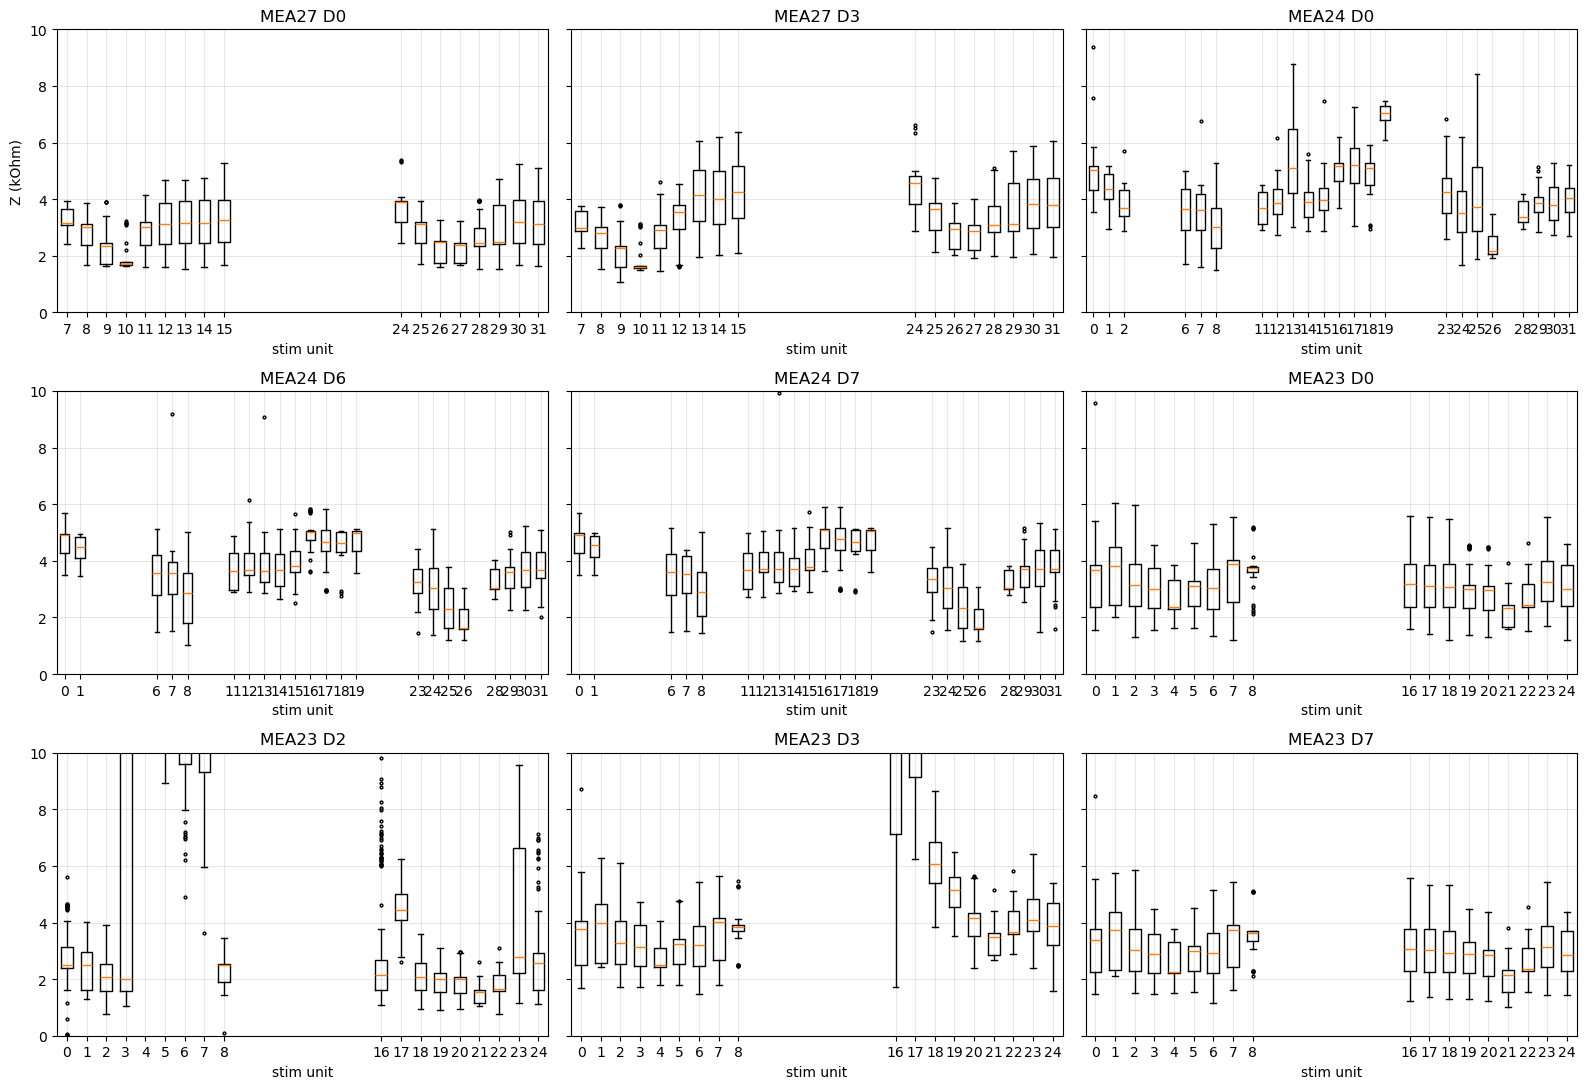

,run,frac_var_explained_by_unit,n_units,within_unit_std_logZ,LSB_spread_pct
0,MEA27 D0,0.146,17,0.113,6.242
1,MEA27 D3,0.355,17,0.109,6.241
2,MEA24 D0,0.297,23,0.107,7.297
3,MEA24 D6,0.437,22,0.096,7.310
4,MEA24 D7,0.438,22,0.096,7.310
5,MEA23 D0,0.088,18,0.135,7.024
6,MEA23 D2,0.590,18,0.186,7.025
7,MEA23 D3,0.707,18,0.127,7.023
8,MEA23 D7,0.095,18,0.138,7.025


In [6]:
fig, axs = plt.subplots(3, 3, figsize=(16, 11), sharey=True)
res=[]
for ax,(k,v) in zip(axs.flat, D.items()):
    s = v[v.Z<LOW].copy()
    units = sorted(s.stim_unit.unique()); keep=[u for u in units if (s.stim_unit==u).sum()>=10]
    ax.boxplot([s.Z[s.stim_unit==u]/1e3 for u in keep], positions=keep, widths=.6, showfliers=True, flierprops=dict(ms=2))
    ax.set_title(k); ax.set_ylim(0,10); ax.set_xlabel('stim unit')
    sk = s[s.stim_unit.isin(keep)]
    within = sk.groupby('stim_unit').logZ.transform(lambda x:x-x.mean()).var()
    res.append(dict(run=k, frac_var_explained_by_unit=1-within/sk.logZ.var(), n_units=len(keep),
                    within_unit_std_logZ=np.sqrt(within), LSB_spread_pct=100*s.groupby('stim_unit').LSB_nA.first().std()/s.LSB_nA.mean()))
axs[0,0].set_ylabel('Z (kOhm)')
plt.tight_layout(); plt.show()
pd.DataFrame(res).round(3)

## 6. Position on the chip (H4): Z vs electrode column / row, and the map

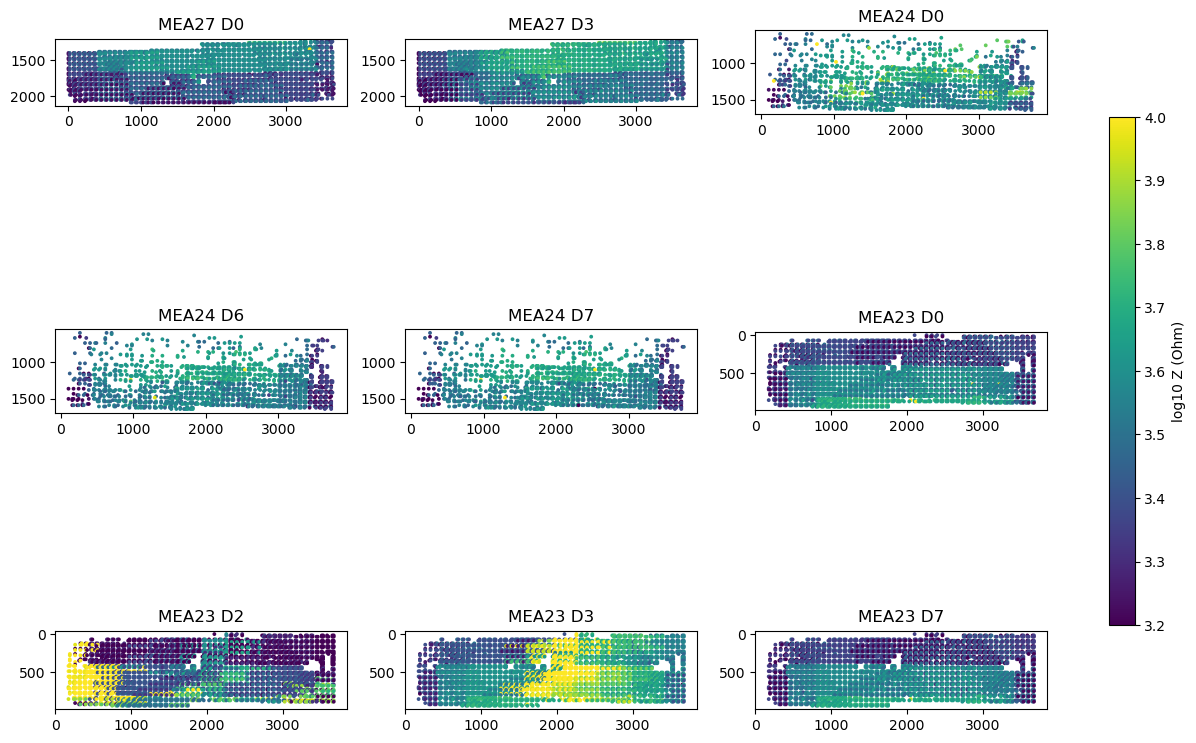

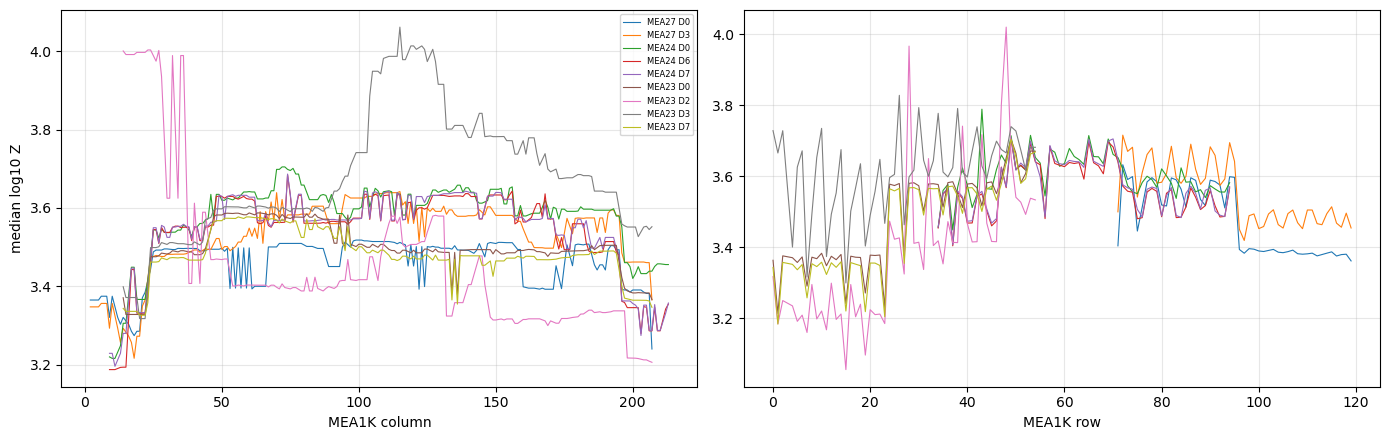

In [7]:
fig, axs = plt.subplots(3, 3, figsize=(16, 11))
for ax,(k,v) in zip(axs.flat, D.items()):
    s = v[v.Z<LOW]
    sc = ax.scatter(s.x, s.y, c=np.log10(s.Z), s=3, cmap='viridis', vmin=3.2, vmax=4)
    ax.invert_yaxis(); ax.set_title(k); ax.set_aspect('equal'); ax.grid(False)
plt.colorbar(sc, ax=axs, label='log10 Z (Ohm)', shrink=.6); plt.show()

fig, axs = plt.subplots(1, 2, figsize=(14, 4.5))
for k,v in D.items():
    s = v[v.Z<LOW]
    axs[0].plot(s.groupby(s.electrode%220).logZ.median().rolling(5,center=True).median(), lw=.8, label=k)
    axs[1].plot(s.groupby(s.electrode//220).logZ.median(), lw=.8)
axs[0].set_xlabel('MEA1K column'); axs[1].set_xlabel('MEA1K row'); axs[0].legend(fontsize=6); axs[0].set_ylabel('median log10 Z')
plt.tight_layout(); plt.show()

## 7. How much does each factor explain? (pooled variance decomposition, one run per chip pair)
Compares *between-run repeatability of the electrode itself* with stim unit and row/column effects.

In [8]:
def r2(s, by):
    within = s.groupby(by).logZ.transform(lambda x:x-x.mean()).var()
    return 1-within/s.logZ.var()
rows=[]
for k,v in D.items():
    s = v[v.Z<LOW].copy()
    s['row']=s.electrode//220; s['col']=s.electrode%220; s['col_bin']=s.col//10; s['row_bin']=s.row//10
    rows.append(dict(run=k, stim_unit=r2(s,'stim_unit'), row_bin10=r2(s,'row_bin'), col_bin10=r2(s,'col_bin'),
                     unit_and_pos=r2(s,['stim_unit','row_bin','col_bin'])))
pd.DataFrame(rows).round(3)

,run,stim_unit,row_bin10,col_bin10,unit_and_pos
0,MEA27 D0,0.157,0.401,0.128,0.688
1,MEA27 D3,0.361,0.278,0.352,0.747
2,MEA24 D0,0.308,0.050,0.248,0.625
3,MEA24 D6,0.437,0.088,0.538,0.772
4,MEA24 D7,0.438,0.086,0.539,0.774
5,MEA23 D0,0.107,0.429,0.133,0.735
6,MEA23 D2,0.590,0.219,0.204,0.858
7,MEA23 D3,0.707,0.024,0.505,0.927
8,MEA23 D7,0.110,0.438,0.134,0.739


## 8. Direct look: same electrodes, first vs last run, coloured by their first-run category

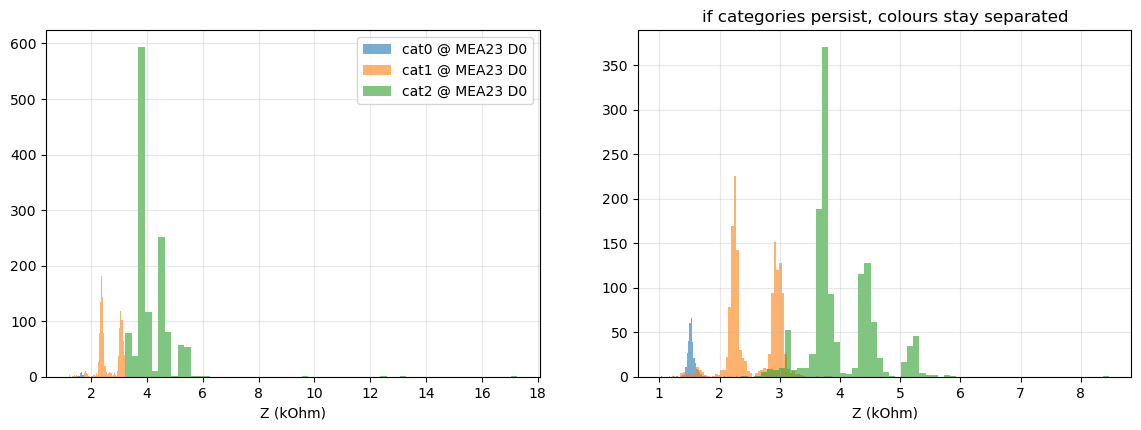

In [9]:
a,b = 'MEA23 D0','MEA23 D7'
m = D[a].merge(D[b], on='electrode', suffixes=('_a','_b')); m=m[(m.Z_a<LOW)&(m.Z_b<LOW)]
gm = GaussianMixture(3, random_state=0).fit(m[['logZ_a']]); cat = gm.predict(m[['logZ_a']])
order = np.argsort(gm.means_.ravel()); rank = np.empty(3,int); rank[order]=np.arange(3); m['cat']=rank[cat]
fig, axs = plt.subplots(1,2, figsize=(14,4.5))
for c in range(3):
    s=m[m.cat==c]; axs[0].hist(s.Z_a/1e3, bins=60, alpha=.6, label=f'cat{c} @ {a}'); axs[1].hist(s.Z_b/1e3, bins=60, alpha=.6, label=f'same electrodes @ {b}')
axs[0].set_xlabel('Z (kOhm)'); axs[1].set_xlabel('Z (kOhm)'); axs[0].legend(); axs[1].set_title('if categories persist, colours stay separated'); plt.show()

## 9. Where are the bands, and are they the same on different chips?
Peaks of the smoothed Z histogram, in **Z** and in **conductance 1/Z**. Equal spacing in Z = series-resistance steps; equal spacing in 1/Z = discrete numbers of parallel contacts.
Also: distance of each electrode from the nearest grid line (uniform would be std 0.29 of a band).

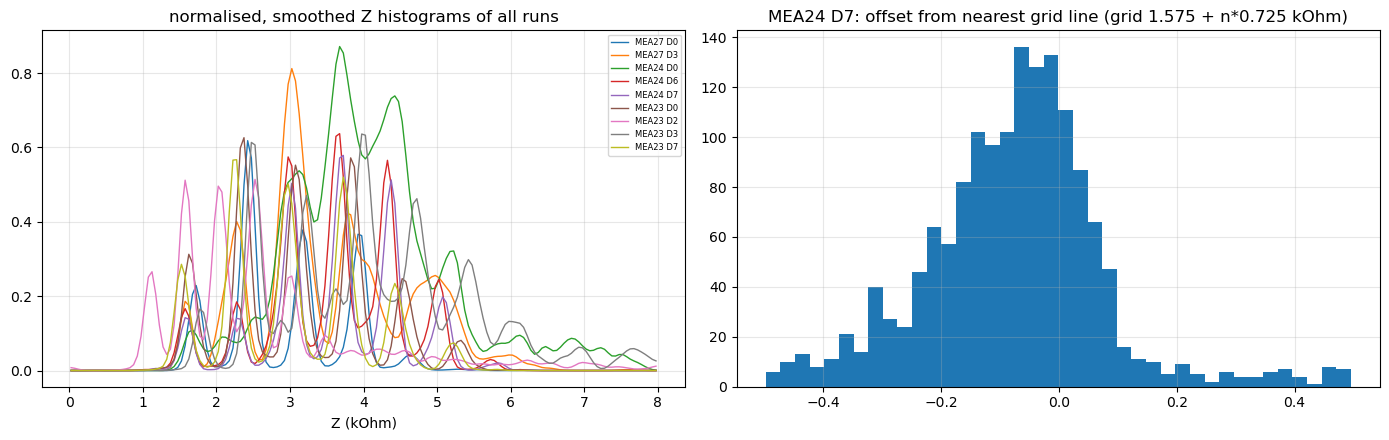

grid-residual std (band units; 0.289 = no grid): 0.153


'        run                                                              peaks_Z_kOhm                                                              dZ                                                dG_mS\n0  MEA27 D0                                            [1.72, 2.43, 3.18, 3.92, 4.62]                                          [0.7, 0.75, 0.75, 0.7]                          [0.035, 0.06, 0.095, 0.175]\n1  MEA27 D3                                            [1.58, 2.28, 3.03, 3.78, 4.97]                                          [0.7, 0.75, 0.75, 1.2]                          [0.06, 0.065, 0.105, 0.195]\n2  MEA24 D0                                            [1.68, 3.12, 3.68, 4.43, 5.22]                                         [1.45, 0.55, 0.75, 0.8]                                         [0.04, 0.05]\n3  MEA24 D6                                      [1.58, 2.28, 2.98, 3.68, 4.32, 5.03]                                      [0.7, 0.7, 0.7, 0.65, 0.7]                      [0.03, 0.04,

In [10]:
from scipy.signal import find_peaks
from scipy.ndimage import gaussian_filter1d
def peaks(x, bins):
    h,e = np.histogram(x,bins); h=gaussian_filter1d(h.astype(float),1.5); c=(e[:-1]+e[1:])/2
    pk,_ = find_peaks(h, prominence=h.max()*.05); return c[pk]
fig, axs = plt.subplots(1,2, figsize=(14,4.5)); rows=[]
for i,(k,v) in enumerate(D.items()):
    z = v.Z[v.Z<LOW].values/1e3
    pz = peaks(z, np.linspace(0,10,201)); pg = peaks(1/z, np.linspace(0,1,201))
    rows.append(dict(run=k, peaks_Z_kOhm=np.round(pz,2).tolist(), dZ=np.round(np.diff(pz),2).tolist(), dG_mS=np.round(np.diff(pg),3).tolist()))
    h,e=np.histogram(z,np.linspace(0,8,161)); axs[0].plot((e[:-1]+e[1:])/2, gaussian_filter1d(h/h.max(),1.5)+i*.0, lw=1, label=k)
axs[0].set_xlabel('Z (kOhm)'); axs[0].set_title('normalised, smoothed Z histograms of all runs'); axs[0].legend(fontsize=6)
s = D['MEA24 D7']; s=s[s.Z<LOW]; b=(s.Z/1e3-1.575)/0.725
axs[1].hist(b-np.round(b), bins=40); axs[1].set_title('MEA24 D7: offset from nearest grid line (grid 1.575 + n*0.725 kOhm)')
plt.tight_layout(); plt.show()
print('grid-residual std (band units; 0.289 = no grid):', round((b-np.round(b)).std(),3))
pd.DataFrame(rows).to_string()

## 10. Is the band index a function of chip geometry (readout / switch matrix)?
Eta^2 of band index against position mod k (a switch-matrix or amplifier-bank pattern would show up for some k).

In [11]:
s = D['MEA24 D7']; s=s[s.Z<LOW].copy(); s['band']=np.round((s.Z/1e3-1.575)/0.725); s['col']=s.electrode%220; s['row']=s.electrode//220
def eta2(g): return 1-s.band.groupby(g).transform(lambda v:v-v.mean()).var()/s.band.var()
pd.DataFrame({'col%k':[eta2(s.col%k) for k in (2,3,4,5,8,10,11,16)], 'row%k':[eta2(s.row%k) for k in (2,3,4,5,8,10,11,16)]}, index=(2,3,4,5,8,10,11,16)).round(3)

,col%k,row%k
2,0.000,0.001
3,0.000,0.000
4,0.061,0.035
5,0.002,0.004
8,0.064,0.041
10,0.003,0.010
11,0.014,0.009
16,0.067,0.058


## 11. Are the bands tied to the *pad* the electrode is bonded to? (MEA24, test17)
`processed/pad2el_mapping.csv` of the first test17 run maps pads of the polyimide device to MEA1K electrodes (a pad covers 1-8 electrodes; only rows with `mea1k_connectivity` are used). The same bond was measured at D0, D6, D7, so this mapping is applied to all three.
Tests: (a) variance of log Z explained by pad identity vs. a shuffled-pad null, (b) pad-level repeatability, (c) Z vs pad column/row on the polyimide, (d) is Z related to the number of electrodes under a pad (parallel contacts)?

In [12]:
pm = pd.read_csv(os.path.join(nas_dir,'devices/headstage_devices/MEA1K24/recordings','2026-11-11_15.10_test17_100_36umP_PT5_Imp','processed','pad2el_mapping.csv'))
pm = pm[pm.mea1k_connectivity.notna()][['mea1k_el','pad_id','pad_x','pad_y']]
pm['pcol'] = pm.pad_x.rank(method='dense').astype(int)-1; pm['prow'] = pm.pad_y.rank(method='dense').astype(int)-1
print('pads:',pm.pad_id.nunique(),' pad grid:',pm.pcol.max()+1,'cols x',pm.prow.max()+1,'rows; electrodes/pad (min,med,max):',pm.groupby('pad_id').mea1k_el.nunique().agg(['min','median','max']).tolist())

def with_pad(lab):
    v = D[lab]; v = v[v.Z<LOW].rename(columns={'electrode':'mea1k_el'})
    return v.merge(pm, on='mea1k_el')
def r2_pad(s, rng, nshuf=200):
    s = s[s.groupby('pad_id').logZ.transform('size')>=2].copy(); k=s.pad_id.nunique()
    f = lambda g: 1-(s.logZ-s.groupby(g).logZ.transform('mean')).var()*(len(s)/(len(s)-k))/s.logZ.var()
    null = [f(rng.permutation(s.pad_id.values)) for _ in range(nshuf)]
    return f(s.pad_id.values), np.mean(null), np.std(null), len(s), k
rng = np.random.default_rng(0); rows=[]
for lab in ['MEA24 D0','MEA24 D6','MEA24 D7']:
    r,nm,ns,n,k = r2_pad(with_pad(lab), rng); rows.append(dict(run=lab, n_el=n, n_pads=k, R2_pad=r, R2_shuffled_pads=nm, null_sd=ns))
pd.DataFrame(rows).round(3)

pads: 571  pad grid: 53 cols x 15 rows; electrodes/pad (min,med,max): [1.0, 3.0, 8.0]


,run,n_el,n_pads,R2_pad,R2_shuffled_pads,null_sd
0,MEA24 D0,1425,404,0.503,0.003,0.025
1,MEA24 D6,1376,389,0.660,0.002,0.025
2,MEA24 D7,1380,391,0.658,0.002,0.024


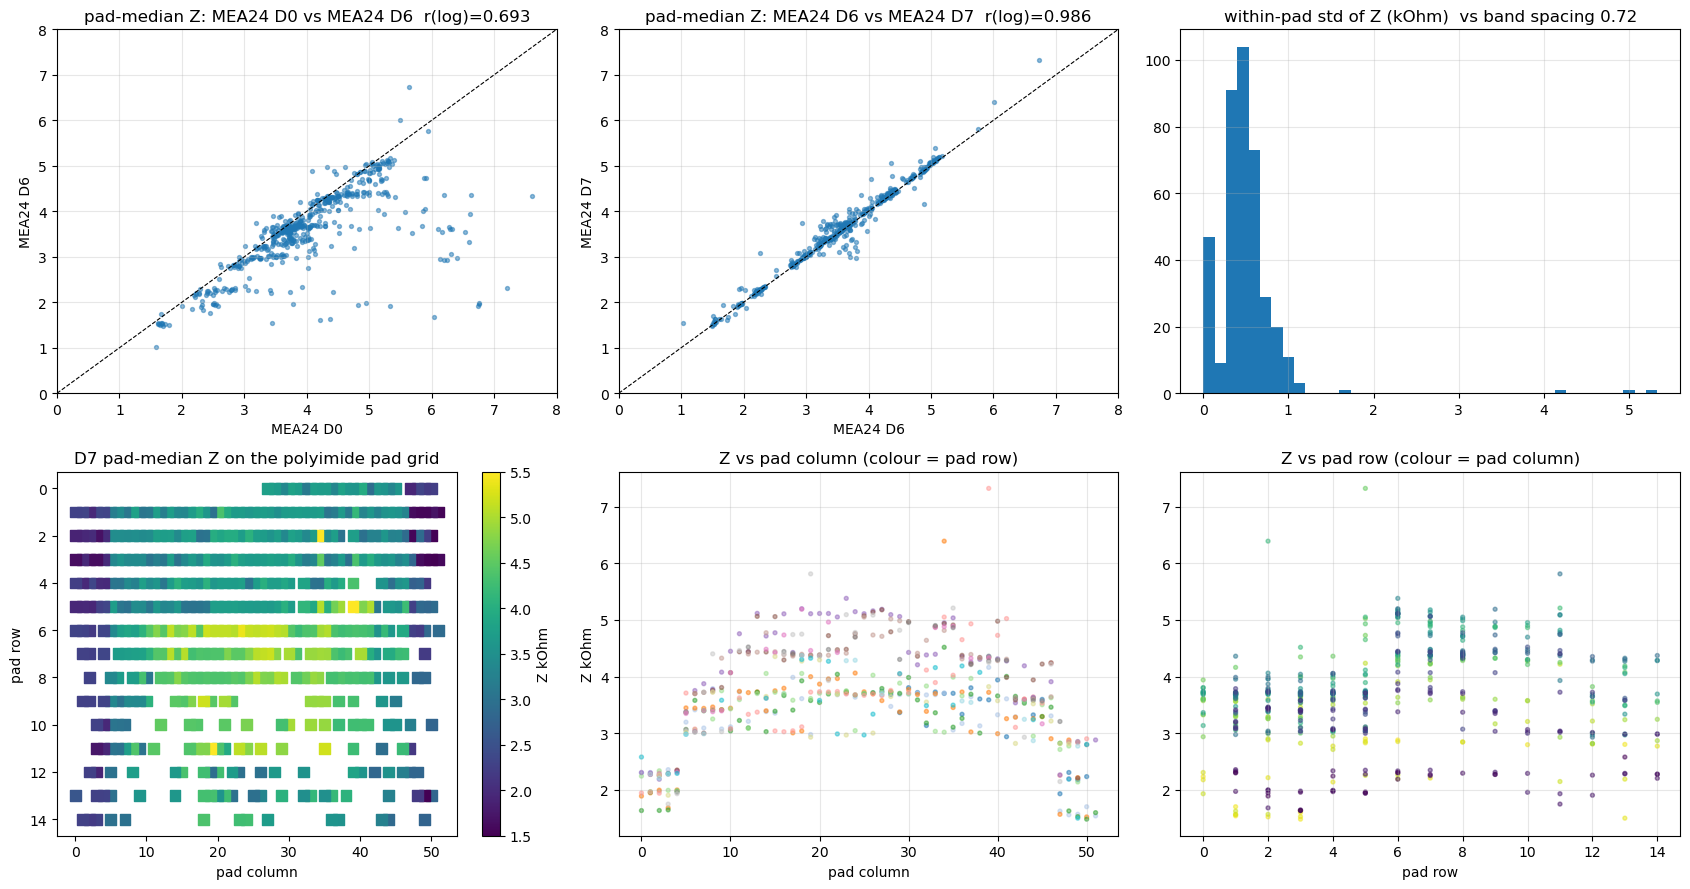

band index eta^2 vs pad col: 0.589 | pad row: 0.202 | (col,row) cell: 1.000 (=unique pad)
corr(Z, #electrodes under pad) = 0.005


In [13]:
P = {lab: with_pad(lab).groupby('pad_id').agg(Z=('Z','median'), sd=('Z','std'), n=('Z','size'), col=('pcol','first'), row=('prow','first')) for lab in ['MEA24 D0','MEA24 D6','MEA24 D7']}
fig, axs = plt.subplots(2, 3, figsize=(17, 9))
for ax,(a,b) in zip(axs[0,:2], [('MEA24 D0','MEA24 D6'),('MEA24 D6','MEA24 D7')]):
    j = P[a].join(P[b], lsuffix='_a', rsuffix='_b').dropna(subset=['Z_a','Z_b'])
    ax.scatter(j.Z_a/1e3, j.Z_b/1e3, s=8, alpha=.5); ax.plot([0,8],[0,8],'k--',lw=.8); ax.set_xlim(0,8); ax.set_ylim(0,8)
    ax.set_title(f'pad-median Z: {a} vs {b}  r(log)={np.corrcoef(np.log(j.Z_a),np.log(j.Z_b))[0,1]:.3f}'); ax.set_xlabel(a); ax.set_ylabel(b)
s = P['MEA24 D7']
axs[0,2].hist(s.sd.dropna()/1e3, bins=40); axs[0,2].set_title('within-pad std of Z (kOhm)  vs band spacing 0.72'); 
sc = axs[1,0].scatter(s.col, s.row, c=s.Z/1e3, cmap='viridis', vmin=1.5, vmax=5.5, s=60, marker='s'); axs[1,0].invert_yaxis(); axs[1,0].set_xlabel('pad column'); axs[1,0].set_ylabel('pad row'); plt.colorbar(sc, ax=axs[1,0], label='Z kOhm'); axs[1,0].set_title('D7 pad-median Z on the polyimide pad grid'); axs[1,0].grid(False)
axs[1,1].scatter(s.col, s.Z/1e3, s=8, alpha=.5, c=s.row, cmap='tab20'); axs[1,1].set_xlabel('pad column'); axs[1,1].set_ylabel('Z kOhm'); axs[1,1].set_title('Z vs pad column (colour = pad row)')
axs[1,2].scatter(s.row, s.Z/1e3, s=8, alpha=.5, c=s.col, cmap='viridis'); axs[1,2].set_xlabel('pad row'); axs[1,2].set_title('Z vs pad row (colour = pad column)')
plt.tight_layout(); plt.show()
s = s.copy(); s['band']=np.round((s.Z/1e3-1.575)/0.725)
eta = lambda g: 1-s.band.groupby(g).transform(lambda v:v-v.mean()).var()/s.band.var()
print('band index eta^2 vs pad col: %.3f | pad row: %.3f | (col,row) cell: %.3f (=unique pad)' % (eta(s.col), eta(s.row), eta([s.col,s.row])))
print('corr(Z, #electrodes under pad) =', round(s.Z.corr(s.n),3))

**Reading of section 11:** pad identity explains most of the log-Z variance (shuffle null ~0) and is reproducible at pad level, so electrodes under the same pad fall in the same band. Because the band is a property of the pad, not the MEA1K electrode, an ADC/measurement artifact on the chip side is excluded; what remains is a pad-linked series resistance (trace/contact), or a pad-level bond state.

## Conclusions (MEA23/24/27 imp runs, Nov 2026)
1. The bands are real structure, not binning: Silverman rejects a single smooth peak in 6/9 runs; grid residual std 0.15 vs 0.29 expected without a grid.
2. Not measurement quantization: 1 ADC LSB of amplitude = ~0.3 Ohm vs 725 Ohm band spacing; DAC amplitude is fixed (30); amplitude is a 400-cycle fit.
3. Not the stim-unit current calibration: LSB varies ~7 % across units, the grid is the same in every unit, stim-unit R2 varies 9-70 % between runs.
4. Spacing is linear in Z (~0.72 kOhm), and the same grid positions appear on MEA24 and MEA27, so it is not "number of parallel contacts" and not bond-specific.
5. **Pad-linked (section 11, MEA24):** pad identity explains 50-66 % of log-Z variance (shuffled-pad null ~0.003); pad-median Z is reproducible D6 vs D7 (r=0.986); Z does not depend on the number of electrodes under a pad (r=0.005). Z vs pad column on the polyimide is a smooth arch (~2 kOhm at the left edge, ~3-5 kOhm in the middle, ~1.5-3 kOhm at the right edge) with several discrete parallel curves, i.e. the band depends on the pad's position/routing. Pad column explains 59 % of band-index variance, pad row 20 %.

**Interpretation (hypothesis):** the categories are classes of the pad -> trace path of the polyimide device (series resistance that depends on routing, plausibly trace length classes), not bond quality classes and not a measurement artifact. Bonding quality then adds on top (D0 -> D6 pad-level r only 0.69 while the bond was still settling).
**Next:** with the polyimide layout, compute trace length/width per pad and test Z_band ~ R_sheet * length / width (the 0.72 kOhm step would give a length per step). Also check whether pads in the same band share a shank/routing layer.
